# Stage 1: what is possible with no training

Every table is read from `results/`; every figure is made by `scripts/analysis.py`. The README says which script writes which file.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.float_format', lambda v: '%.4g' % v)
frontier = pd.read_csv('results/classical_frontier.csv')
cols = ['label', 'precision', 'field_reads_mean', 'ns_lowest', 'cold_ns_median',
        'radial_median_um', 'radial_95_um', 'worst_band_median_um']

## 1. The classical frontier

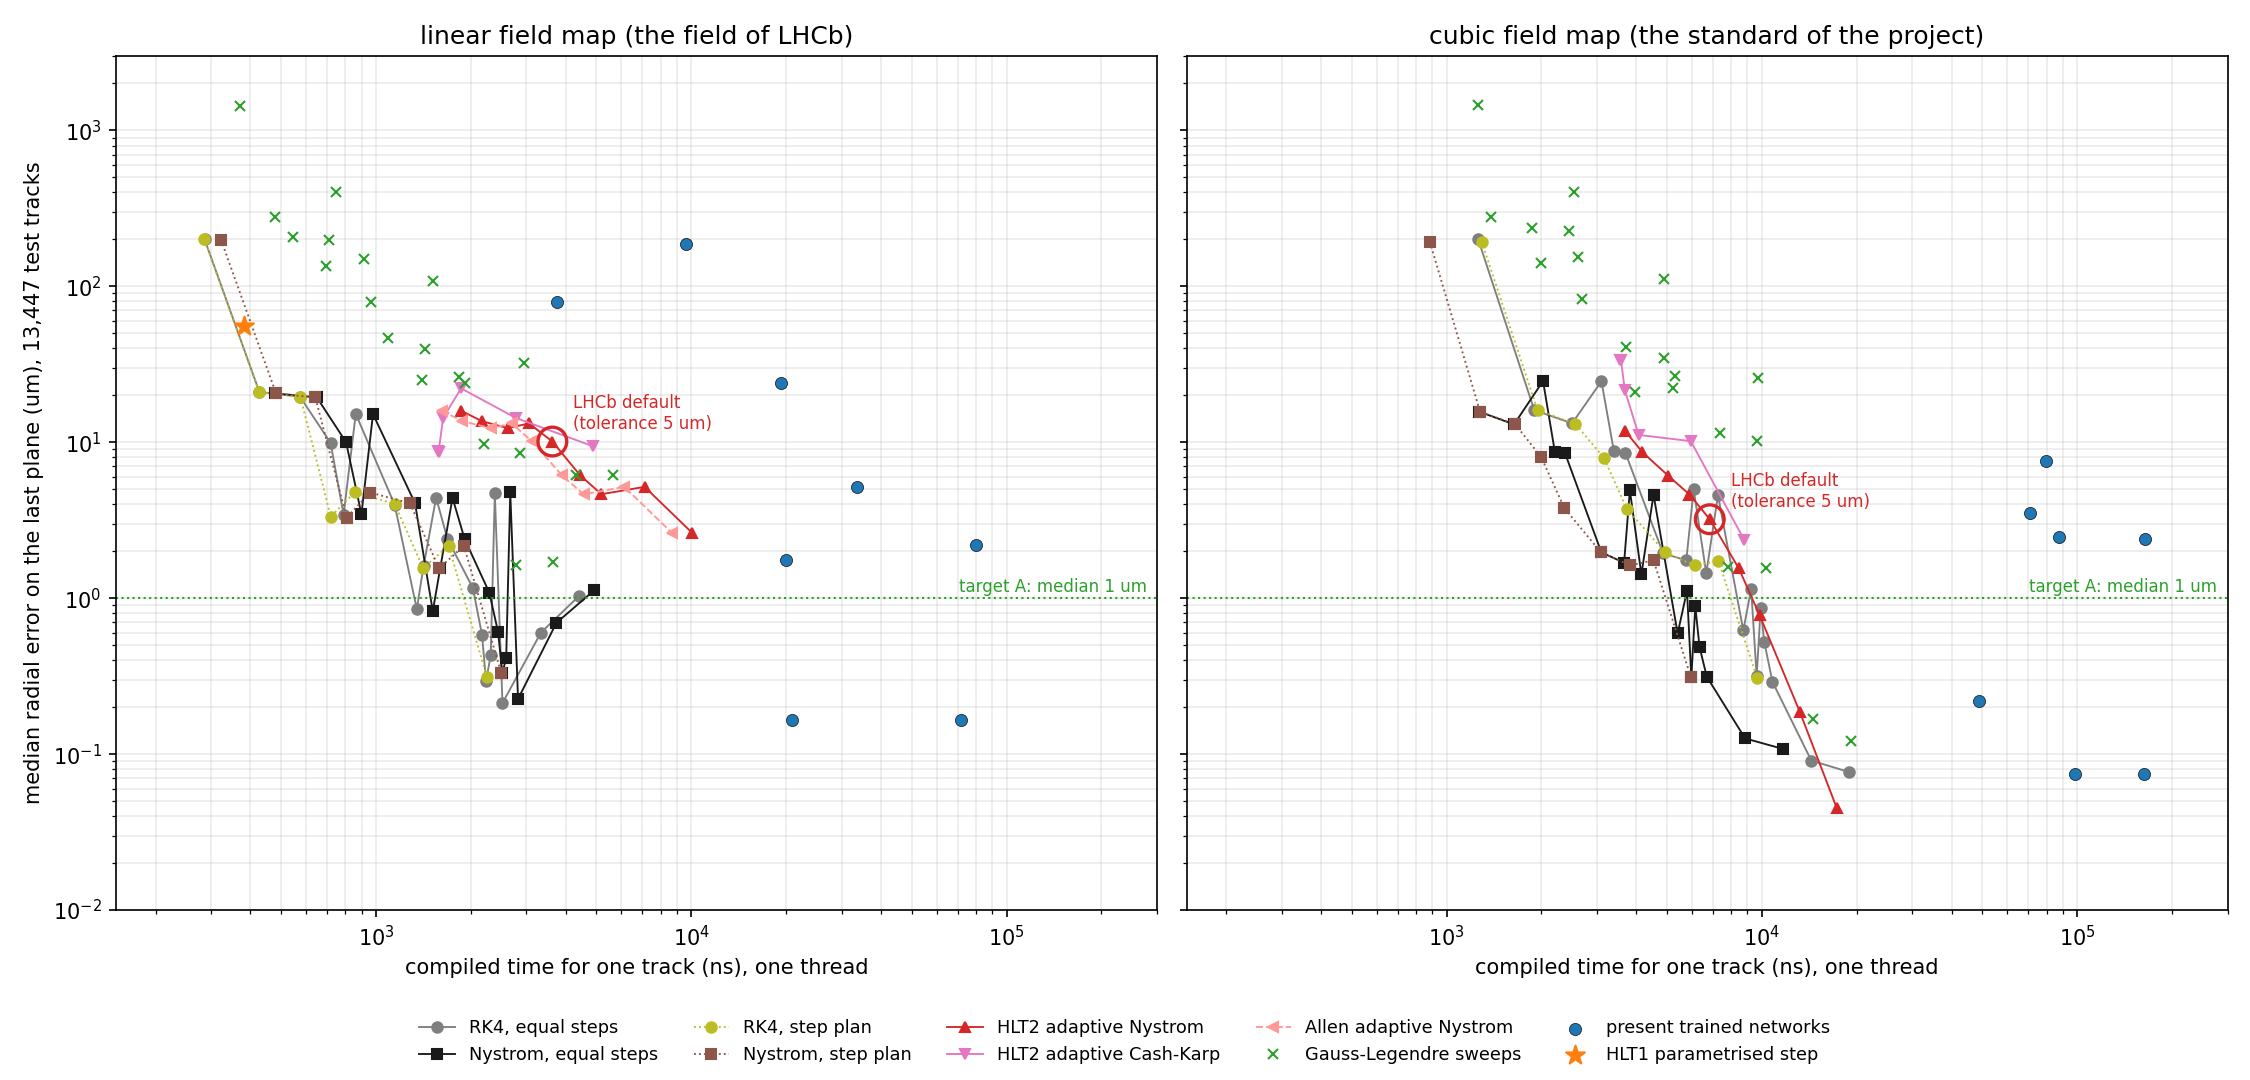

In [2]:
display(Image('figures/frontier.png'))

In [3]:
pd.read_csv('results/cheapest_methods.csv')

,map,target,family,method,field_reads,ns,radial_median_um,radial_95_um,worst_band_median_um
0,linear,target A,"RK4, equal steps","RK4, 31 equal steps",124,2169,0.5819,7.027,2.673
1,linear,target A,"Nystrom, equal steps","Nystrom, 31 equal steps",63,2440,0.606,7.123,2.74
2,linear,target A,"RK4, step plan","RK4 on a step plan, 32 steps",128,2249,0.3125,5.518,1.559
3,linear,target A,"Nystrom, step plan","Nystrom on a step plan, 32 steps",65,2499,0.3298,5.486,1.557
4,linear,target A,HLT2 adaptive Nystrom,none,NaN,NaN,NaN,NaN,NaN
5,linear,target A,HLT2 adaptive Cash-Karp,none,NaN,NaN,NaN,NaN,NaN
6,linear,target A,Allen adaptive Nystrom,none,NaN,NaN,NaN,NaN,NaN
7,linear,target A,Gauss-Legendre sweeps,none,NaN,NaN,NaN,NaN,NaN
8,linear,target B,"RK4, equal steps","RK4, 19 equal steps",76,1347,0.8541,14.46,4.843
9,linear,target B,"Nystrom, equal steps","Nystrom, 19 equal steps",39,1514,0.8266,14.2,4.635


## 2. The error of a fixed-step integrator and the grid of the map

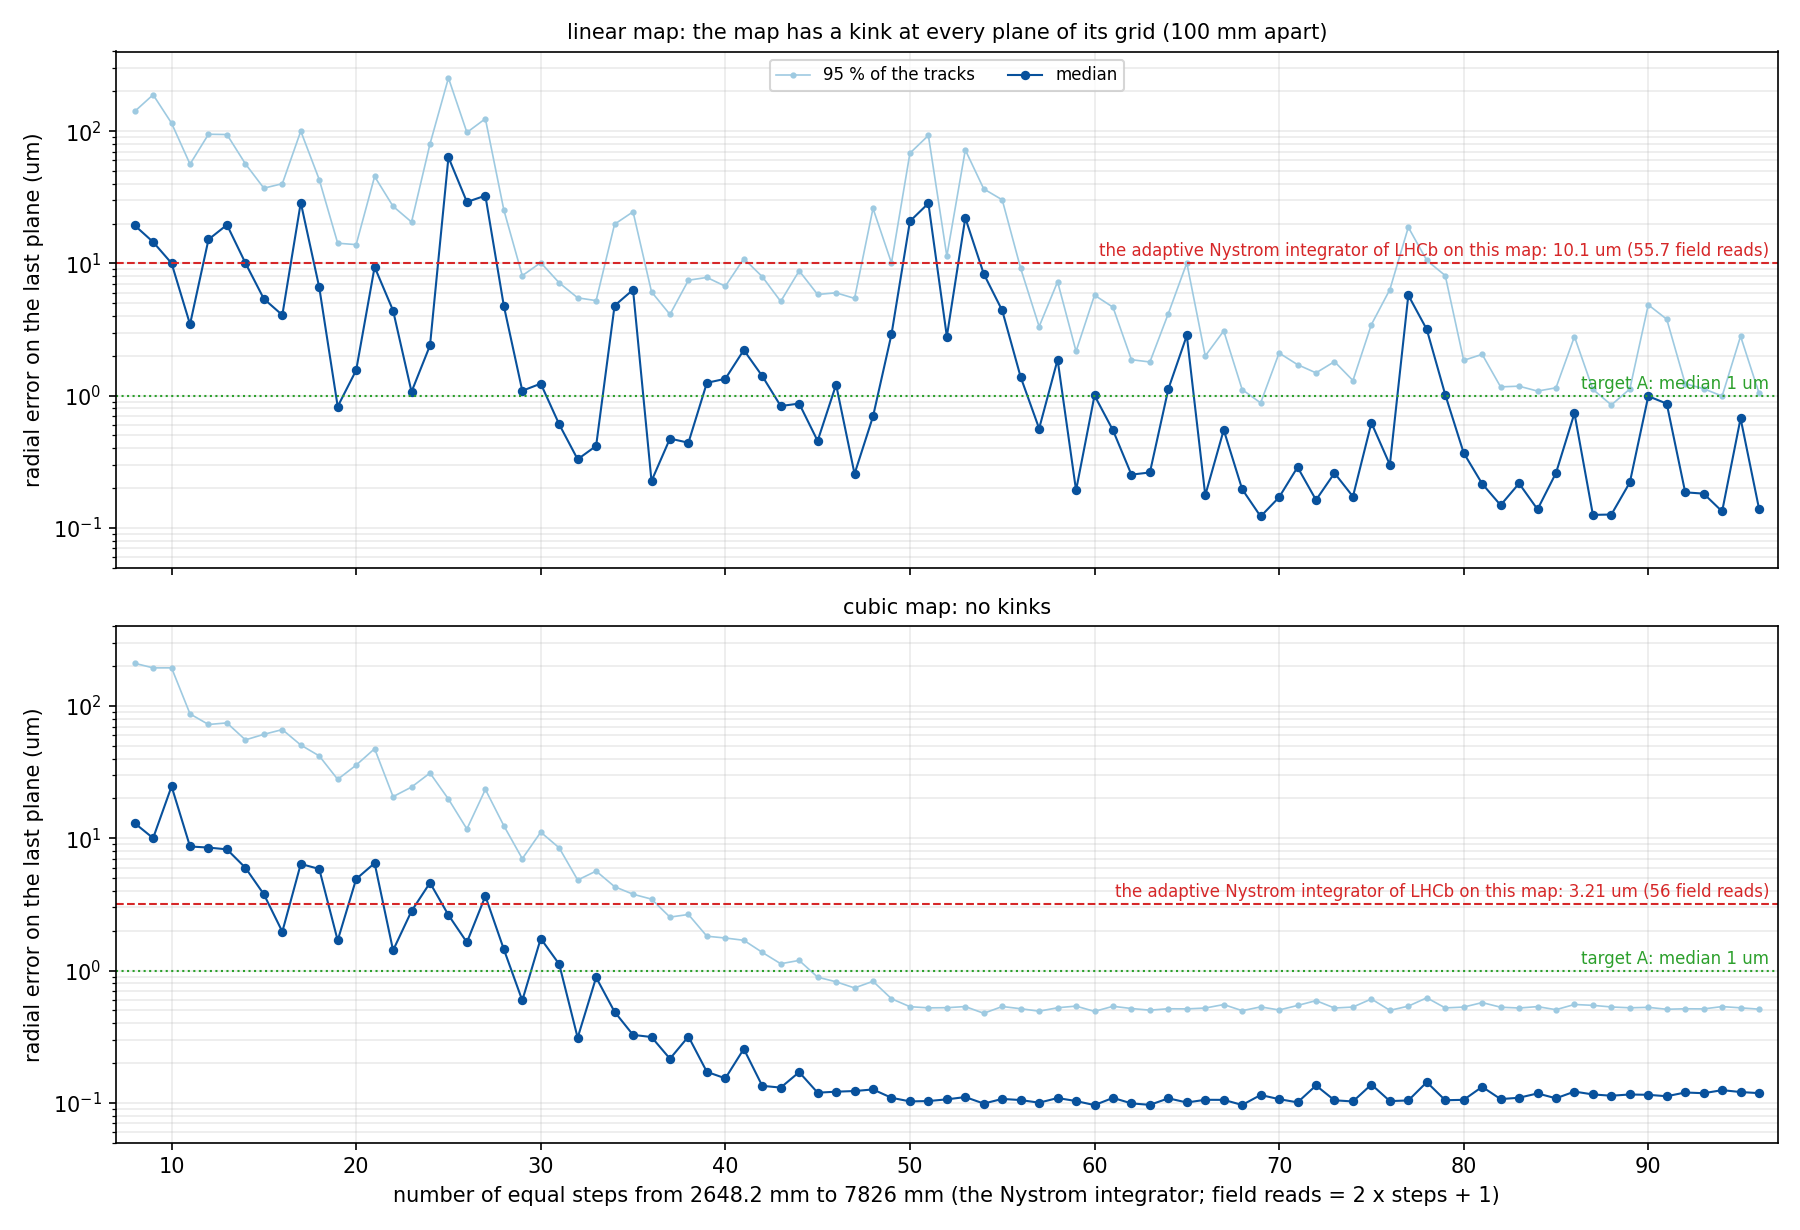

In [4]:
display(Image('figures/error_against_the_number_of_steps.png'))

In [5]:
scan = pd.read_csv('results/step_length_scan.csv')
equal = scan[scan.family == 'equal steps']
equal.pivot_table(index='steps', columns=['map_of_the_field', 'sample'],
                  values=['radial_median_um', 'radial_95_um'])

radial_95_um                          radial_median_um  \
map_of_the_field        cubic          linear                     cubic   
sample                   test training   test training             test   
steps                                                                     
8                       210.7    213.9  140.8    144.8            13.02   
9                       194.4    166.2  188.4    176.8            10.03   
10                      194.5    190.4  114.9    114.6            24.71   
11                      87.21    85.03  56.24    51.81            8.669   
12                      72.54    74.53  94.71    90.74            8.509   
13                      74.57    75.08  94.22    94.61            8.248   
14                      55.49    49.61  56.56    52.19            5.987   
15                      61.11    63.72  37.03    35.75            3.772   
16                      66.37    66.02  40.04    40.06            1.967   
17                      50.73    50.41    100      101            6.397   
18                      41.97    43.01     43    41.12            5.861   
19                      27.91    26.55   14.2       14            1.689   
20                      35.75    36.47  13.86    13.76            4.922   
21                      47.59    47.01  45.38    47.17            6.489   
22                      20.65    21.58  26.99    29.72            1.422   
23                       24.4    24.37  20.54    20.75            2.817   
24                      31.16    31.28  79.98    73.36            4.609   
25                      19.79    19.46  252.2      237            2.627   
26                      11.75    12.33  97.69    98.13            1.634   
27                      23.42    21.57  124.1    118.1            3.658   
28                      12.44    12.17  25.36    24.61            1.448   
29                       7.01    6.978  8.077    8.061            0.594   
30                      11.13    11.07  10.13    9.676            1.745   
31                      8.463    8.019  7.123    6.008            1.117   
32                      4.835    4.742  5.486    5.079           0.3103   
33                       5.65    5.294  5.228      4.9           0.8874   
34                      4.308    4.314  19.77    18.67           0.4871   
35                      3.775     3.76  24.54    23.26           0.3261   
36                      3.468     3.44  6.092    5.662           0.3142   
37                      2.535     2.53  4.107    3.973           0.2152   
38                      2.654    2.487  7.453    6.967           0.3169   
39                      1.817     1.87  7.826    7.361           0.1713   
40                      1.762    1.637  6.712    6.517            0.153   
41                      1.693    1.654  10.86    11.57           0.2554   
42                      1.372    1.242  7.934     7.57           0.1343   
43                      1.126    1.093  5.153    5.079           0.1303   
44                      1.193    1.091  8.784     8.78           0.1705   
45                     0.8907   0.8738  5.817     5.18           0.1192   
46                      0.822   0.8011  5.987    5.981           0.1213   
47                     0.7384   0.7067  5.435    5.289           0.1227   
48                     0.8293   0.7559  26.04    24.66           0.1261   
49                     0.6119   0.5934  10.07    10.02           0.1091   
50                     0.5328   0.5256  68.08    66.51           0.1024   
51                     0.5222   0.5141  92.76    91.68            0.103   
52                     0.5236   0.5149  11.33    11.48           0.1061   
53                      0.534   0.5023  72.05     71.5           0.1104   
54                     0.4749   0.4663  36.54    33.31          0.09862   
55                     0.5346   0.5134  30.22       27           0.1069   
56                     0.5142   0.5282  9.165    8.381           0.1048   
57                     0.4927   0.4898  3.

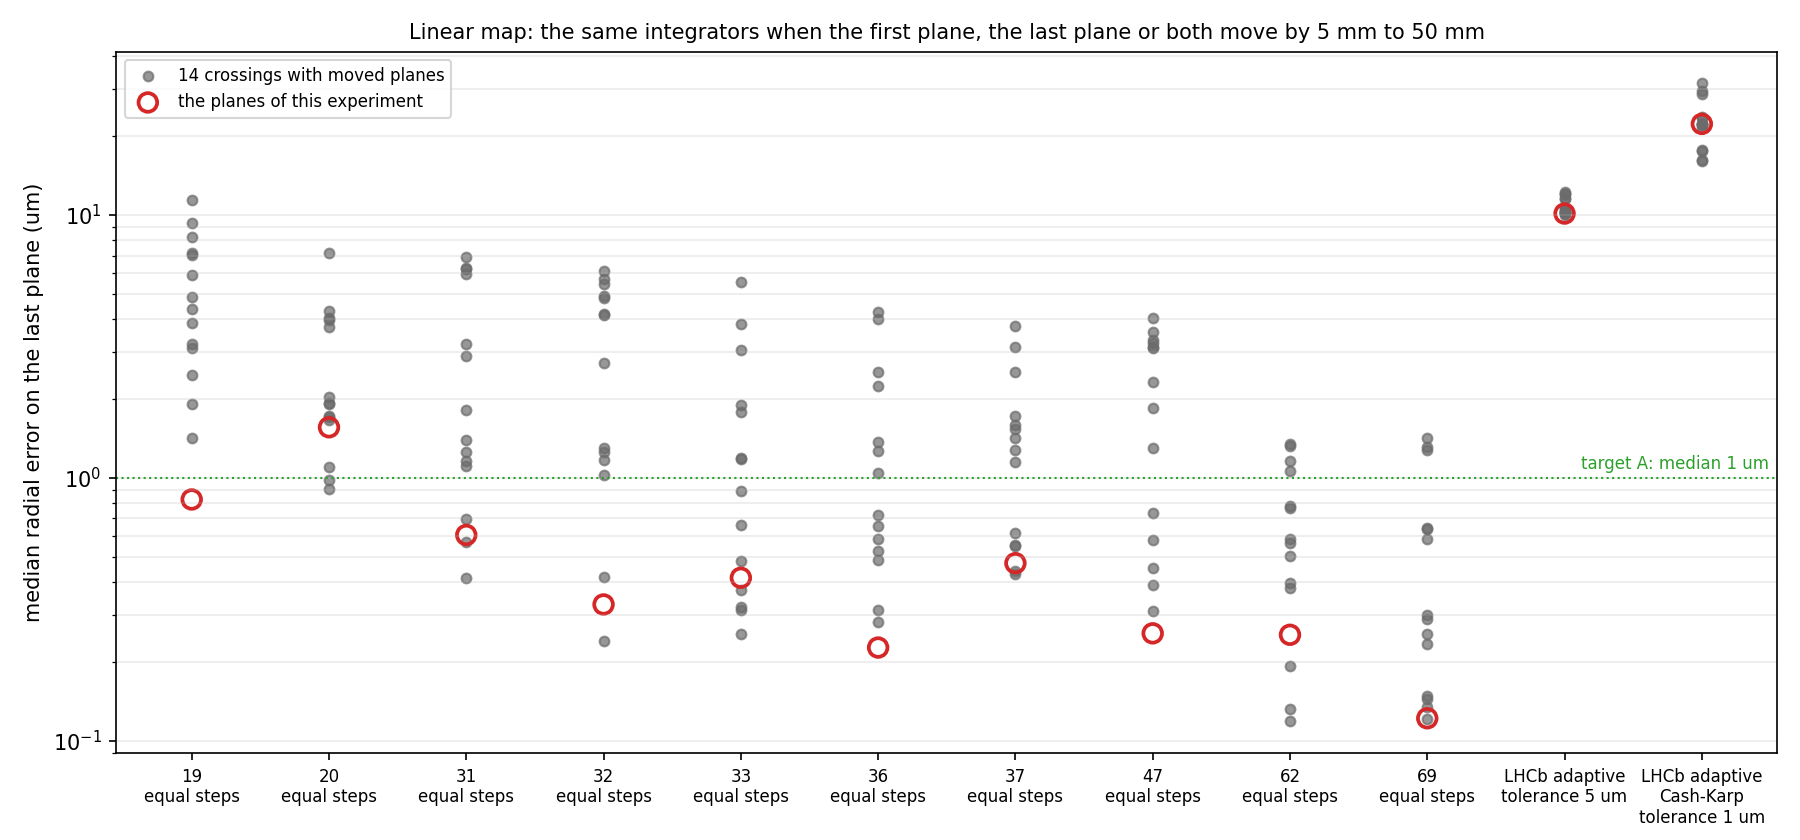

In [6]:
display(Image('figures/shifted_planes.png'))

In [7]:
shifted = pd.read_csv('results/shifted_planes.csv')
shifted.pivot_table(index=['first_plane_mm', 'last_plane_mm'], columns='label',
                    values='radial_median_um')

label                         HLT2 adaptive Cash-Karp, tolerance 1 um  \
first_plane_mm last_plane_mm                                            
2623           7801                                             16.01   
               7826                                             16.17   
2648           7826                                             22.16   
               7831                                             22.18   
               7836                                             22.15   
               7851                                             22.06   
               7876                                             21.91   
2653           7826                                              23.3   
2658           7826                                             23.59   
2665           7826                                             21.36   
2673           7826                                             17.56   
               7851                                             17.58   
2698           7826                                             28.84   
               7876                                             29.68   
2700           7800                                              31.6   

label                         HLT2 adaptive Nystrom, tolerance 5 um  \
first_plane_mm last_plane_mm                                          
2623           7801                                           10.53   
               7826                                           10.61   
2648           7826                                           10.11   
               7831                                           10.12   
               7836                                           10.14   
               7851                                           10.21   
               7876                                           10.28   
2653           7826                                           9.989   
2658           7826                                           10.12   
2665           7826                                           10.33   
2673           7826                                           11.47   
               7851                                           11.57   
2698           7826                                           12.03   
               7876                                           12.18   
2700           7800                                           11.99   

label                         Nystrom, 19 equal steps  \
first_plane_mm last_plane_mm                            
2623           7801                             3.889   
               7826                             3.124   
2648           7826                            0.8266   
               7831                             1.412   
               7836                             1.904   
               7851                             3.214   
               7876                             5.918   
2653           7826                             4.368   
2658           7826                             7.052   
2665           7826                             9.337   
2673           7826                             2.461   
               7851                             4.886   
2698           7826                             11.36   
               7876                             7.176   
2700           7800                             8.201   

label                         Nystrom, 20 equal steps  \
first_plane_mm last_plane_mm                            
2623           7801                             1.721   
               7826                             1.696   
2648           7826                             1.555   
               7831                             1.928   
               7836                             2.034   
               7851                             1.097   
               7876                             1.664   
2653           7826                             4.301   
2658      

## 3. Field reads and time

In [8]:
both = frontier[frontier.family.isin(['RK4, equal steps', 'Nystrom, equal steps'])]
both.pivot_table(index='steps', columns=['map_of_the_field', 'family'],
                 values=['field_reads_mean', 'ns_lowest'])

field_reads_mean                                        \
map_of_the_field                cubic                                linear   
family           Nystrom, equal steps RK4, equal steps Nystrom, equal steps   
steps                                                                         
4                                 NaN               16                  NaN   
6                                  13               24                   13   
8                                  17               32                   17   
10                                 21               40                   21   
11                                 23               44                   23   
12                                 25               48                   25   
16                                 33               64                   33   
19                                 39               76                   39   
20                                 41               80                   41   
22                                 45               88                   45   
24                                 49               96                   49   
29                                 59              116                   59   
31                                 63              124                   63   
32                                 65              128                   65   
33                                 67              132                   67   
34                                 69              136                   69   
36                                 73              144                   73   
48                                 97              192                   97   
64                                129              256                  129   

                                             ns_lowest                   \
map_of_the_field                                 cubic                    
family           RK4, equal steps Nystrom, equal steps RK4, equal steps   
steps                                                                     
4                              16                  NaN             1260   
6                              24                 1268             1898   
8                              32                 1638             2503   
10                             40                 2024             3101   
11                             44                 2207             3396   
12                             48                 2377             3694   
16                             64                 3099             4864   
19                             76                 3658             5762   
20                             80                 3816             6081   
22                             88                 4150             6666   
24                             96                 4536             7262   
29                            116                 5410             8736   
31                            124                 5791             9254   
32                            128                 5978             9633   
33                            132                 6153             9917   
34                            136                 6346        1.018e+04   
36                            144                 6690        1.081e+04   
48                            192                 8855        1.436e+04   
64                            256            1.166e+04        1.896e+04   

                                                        
map_of_the_field               linear                   
family           Nystrom, equal steps RK4, equal steps  
steps                                                   
4                                 NaN            286.1  
6                               477.9            426.7  
8                               649.5            574.5  
10                              803.8            717.8  
11                   

## 4. The LHCb integrators at other tolerances

In [9]:
frontier[frontier.family.isin(['HLT2 adaptive Nystrom', 'HLT2 adaptive Cash-Karp',
                               'Allen adaptive Nystrom'])][['map_of_the_field'] + cols]

,map_of_the_field,label,precision,field_reads_mean,ns_lowest,cold_ns_median,radial_median_um,radial_95_um,worst_band_median_um
55,linear,"HLT2 adaptive Nystrom (STEP), tolerance 0.1 um",double,159.1,1.004e+04,1.879e+04,2.638,10.44,5.725
56,linear,"HLT2 adaptive Nystrom (STEP), tolerance 0.3 um",double,110.1,7116,1.532e+04,5.177,20.85,10.63
57,linear,"HLT2 adaptive Nystrom (STEP), tolerance 1 um",double,81.09,5191,1.336e+04,4.645,38.42,29.83
58,linear,"HLT2 adaptive Nystrom (STEP), tolerance 2 um",double,68.97,4444,1.23e+04,6.132,33.64,16.81
59,linear,"HLT2 adaptive Nystrom (STEP), tolerance 5 um",double,55.75,3627,1.072e+04,10.11,38.8,16.21
60,linear,"HLT2 adaptive Nystrom (STEP), tolerance 10 um",double,47.89,3059,9784,13.21,64.88,30.06
61,linear,"HLT2 adaptive Nystrom (STEP), tolerance 20 um",double,41.1,2619,8812,12.32,108.5,67.66
62,linear,"HLT2 adaptive Nystrom (STEP), tolerance 50 um",double,33.67,2165,7629,13.67,64.36,29.46
63,linear,"HLT2 adaptive Nystrom (STEP), tolerance 100 um",double,29.19,1864,6788,15.93,86.28,36.21
64,linear,"HLT2 adaptive Cash-Karp, tolerances x 0.1",double,115.5,4862,1.153e+04,9.452,56.69,34.86


## 5. The two readings of the map

In [10]:
two = pd.read_csv('results/two_readings_of_the_map.csv')
bands = [c for c in two.columns if c.startswith('radial_median_um_') and c.endswith('_gev')]
two[['label', 'field_reads_mean', 'radial_median_um', 'radial_95_um'] + bands]

,label,field_reads_mean,radial_median_um,radial_95_um,radial_median_um_0_3_gev,radial_median_um_3_8_gev,radial_median_um_8_20_gev,radial_median_um_20_50_gev,radial_median_um_above_50_gev
0,"The linear reading, integrated with 2,048 steps",8192,22.95,162.7,80.1,38.5,16.64,7.265,2.86
1,"HLT2 adaptive Nystrom, linear reading (as LHCb runs it)",55.75,25.9,169,83.68,41.72,17.84,7.334,3.048
2,"HLT2 adaptive Cash-Karp, linear reading (as LHCb runs it)",42.57,31.68,203,102.1,55.78,21.54,8.071,2.836
3,HLT2 adaptive Nystrom on the cubic reading,56.05,3.209,15.51,4.445,4.29,2.917,1.241,1.036
4,HLT2 adaptive Cash-Karp on the cubic reading,42.8,11.15,98.53,39.26,22.94,6.302,3.915,3.628


## 6. Steps of unequal length

In [11]:
display(pd.read_csv('results/chosen_plans.csv'))
pd.read_csv('results/cost_of_a_step_along_z.csv').pivot_table(
    index='start_of_the_step_mm', columns='map', values='mean_contribution_to_the_final_error_um')

,map_of_the_field,integrator,steps,beta,training_radial_median_um,training_radial_95_um
0,cubic,nystrom_plan,4,0.5,183.9,5182
1,cubic,nystrom_plan,6,0,14.89,231.5
2,cubic,nystrom_plan,8,0,12.66,213.9
3,cubic,nystrom_plan,10,0.1,7.866,122.5
4,cubic,nystrom_plan,12,0.1,3.736,70.74
5,cubic,nystrom_plan,16,0,1.924,66.02
6,cubic,nystrom_plan,20,0.1,1.543,28
7,cubic,nystrom_plan,24,0.2,1.669,18.21
8,cubic,nystrom_plan,32,0,0.2874,4.742
9,cubic,rk4_plan,4,0.5,185.8,5217


map,cubic,linear
start_of_the_step_mm,,
2648,0.02631,0.5219
2729,0.001155,0.7784
2810,0.0008839,0.008494
2891,0.001054,0.6941
2972,0.004527,0.2634
3053,0.006458,1.329
3134,0.001355,0.7751
3215,0.001426,0.00831
3295,0.002363,0.1696


## 7. The floor of each layout

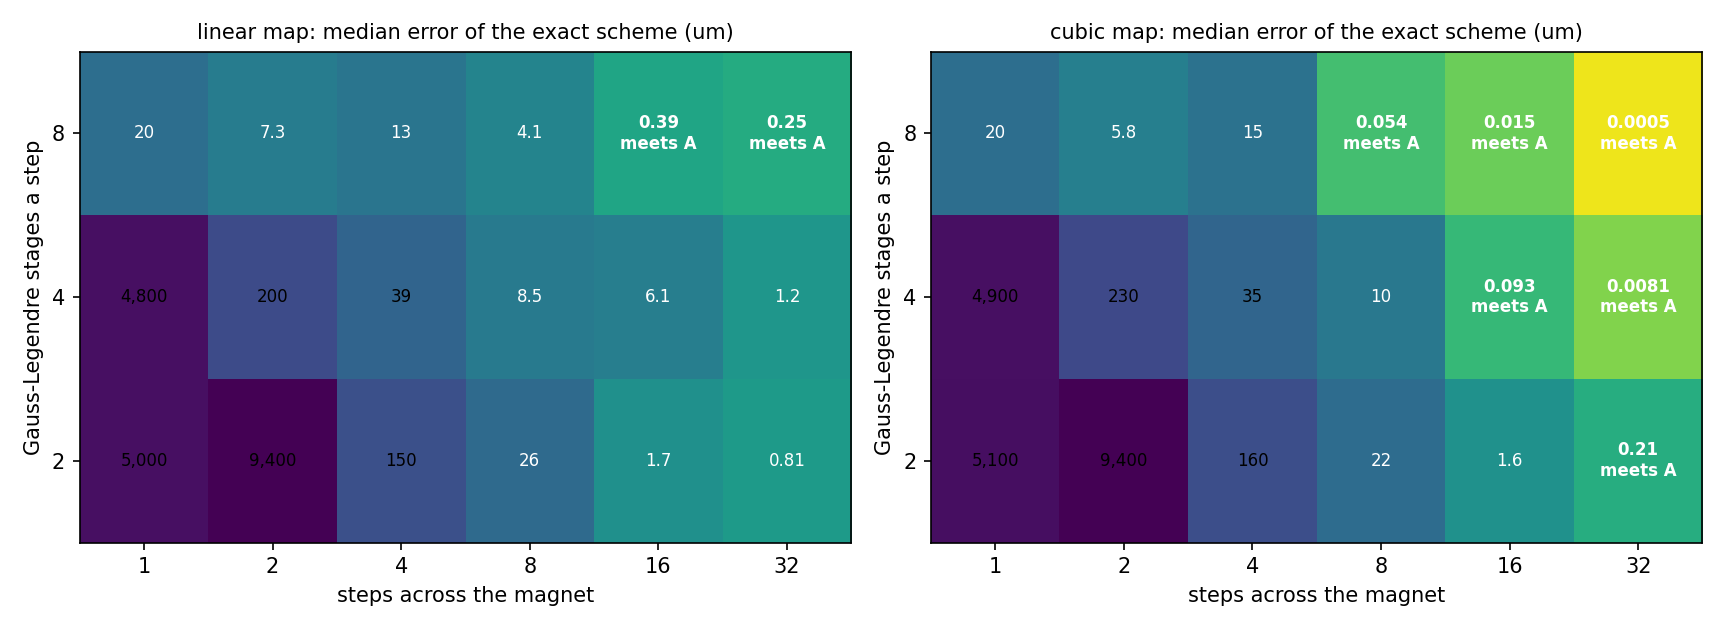

In [12]:
display(Image('figures/floor_of_the_layouts.png'))

In [13]:
floor = pd.read_csv('results/floor_of_the_layouts.csv')
floor[['map_of_the_field', 'steps', 'stages', 'radial_median_um', 'radial_95_um',
       'worst_band_median_um', 'converged']]

,map_of_the_field,steps,stages,radial_median_um,radial_95_um,worst_band_median_um,converged
0,linear,1,2,5026,1.76e+04,8221,True
1,linear,1,4,4843,3.446e+04,1.601e+04,True
2,linear,1,8,19.82,946,154.5,True
3,linear,2,2,9436,4.05e+04,2.951e+04,True
4,linear,2,4,198.2,1142,635.8,True
5,linear,2,8,7.315,108.4,32.04,True
6,linear,4,2,150.9,2088,573.2,True
7,linear,4,4,39.45,217.4,126.3,True
8,linear,4,8,12.55,80.37,38.46,True
9,linear,8,2,26.3,158.8,86.99,True


## 8. What a chained network would cost at target A

In [14]:
pd.read_csv('results/what_a_chained_network_costs.csv')

,map,steps,stages,stage_points,floor_median_um,floor_95_um,reads_ns,lowest_time_ns_width_16,lowest_time_ns_width_32,lowest_time_ns_width_64,fastest_classical_method,fastest_classical_ns
0,linear,16,8,128,0.3912,2.303,1352,2629,3511,5090,"RK4, 31 equal steps",2169
1,linear,32,8,256,0.2466,1.024,2705,5258,7022,1.018e+04,"RK4, 31 equal steps",2169
2,cubic,8,8,64,0.05379,1.442,4231,4870,5310,6100,"Nystrom, 29 equal steps",5410
3,cubic,16,4,64,0.09327,1.883,4231,5508,6390,7968,"Nystrom, 29 equal steps",5410
4,cubic,16,8,128,0.01528,0.1217,8462,9739,1.062e+04,1.22e+04,"Nystrom, 29 equal steps",5410
5,cubic,32,2,64,0.2135,3.481,4231,6785,8548,1.171e+04,"Nystrom, 29 equal steps",5410
6,cubic,32,4,128,0.008148,0.08349,8462,1.102e+04,1.278e+04,1.594e+04,"Nystrom, 29 equal steps",5410
7,cubic,32,8,256,0.0005008,0.005872,1.692e+04,1.948e+04,2.124e+04,2.44e+04,"Nystrom, 29 equal steps",5410


## 9. Every method of the stage

In [15]:
frontier.sort_values(['map_of_the_field', 'ns_lowest'])[['map_of_the_field'] + cols]

,map_of_the_field,label,precision,field_reads_mean,ns_lowest,cold_ns_median,radial_median_um,radial_95_um,worst_band_median_um
173,cubic,"Gauss-Legendre, 2 steps x 2 stages, 1 sweeps",float,8,658.7,3982,1.08e+04,6.979e+04,5.73e+04
149,cubic,"Nystrom on a step plan, 4 steps",float,9,885.5,6262,192.8,5561,1136
174,cubic,"Gauss-Legendre, 2 steps x 2 stages, 2 sweeps",float,12,978.1,4469,9438,4.189e+04,3.123e+04
103,cubic,"RK4, 4 equal steps",float,16,1260,7354,200.9,2891,774.5
176,cubic,"Gauss-Legendre, 2 steps x 4 stages, 1 sweeps",float,16,1263,6717,1461,3.381e+04,2.711e+04
122,cubic,"Nystrom, 6 equal steps",float,13,1268,8726,15.72,271.6,61.49
150,cubic,"Nystrom on a step plan, 6 steps",float,13,1277,8867,15.72,271.6,61.49
140,cubic,"RK4 on a step plan, 4 steps",float,16,1292,7314,193.7,5647,1152
175,cubic,"Gauss-Legendre, 2 steps x 2 stages, 3 sweeps",float,16,1299,4799,9432,4.061e+04,2.963e+04
179,cubic,"Gauss-Legendre, 4 steps x 2 stages, 1 sweeps",float,16,1379,6772,277.6,9451,7173
